# Phase I: Visualizing Logistic Regression Behavior

This notebook analyzes the held-out predictions in `prediction_results.csv` as a black box. It focuses on error patterns and on how changing the probability threshold changes false negatives and false positives. It does not retrain the model.


In [7]:
%pip install seaborn
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

sns.set_theme(style="whitegrid", context="notebook")

# Tries the current directory first, then the uploaded-file folder used in this workspace.
CSV_PATH = Path("prediction_results.csv")
if not CSV_PATH.exists():
    CSV_PATH = Path("upload/prediction_results.csv")
if not CSV_PATH.exists():
    raise FileNotFoundError("Place prediction_results.csv beside this notebook or edit CSV_PATH.")

df = pd.read_csv(CSV_PATH)
required = {"actual", "predicted", "probability", "Glucose", "BMI", "Age"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {sorted(missing)}")

# Check labels and probability values before plotting.
if not set(df["actual"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected binary actual labels coded as 0 and 1.")
if not set(df["predicted"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected binary predicted labels coded as 0 and 1.")
if not df["probability"].between(0, 1).all():
    raise ValueError("probability values must be between 0 and 1.")

# Give each row an interpretable outcome group.
def outcome_group(row):
    if row.actual == 1 and row.predicted == 1: return "True positive"
    if row.actual == 0 and row.predicted == 0: return "True negative"
    if row.actual == 1 and row.predicted == 0: return "False negative"
    return "False positive"

df["error_group"] = df.apply(outcome_group, axis=1)

# In this dataset, zero is used as a missing-value code for these measurements.
# Keep the original CSV intact; use this copy only for feature visualizations.
zero_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_visual = df.copy()
for col in zero_missing_cols:
    if col in df_visual.columns:
        df_visual.loc[df_visual[col] == 0, col] = np.nan

print("Zero values treated as missing for plots:")
print(df[zero_missing_cols].eq(0).sum())
print(f"Loaded {len(df)} held-out records from {CSV_PATH}")
print("Outcome groups:")
print(df["error_group"].value_counts().reindex(["True negative", "False positive", "False negative", "True positive"], fill_value=0))

Zero values treated as missing for plots:
Glucose           1
BloodPressure    12
SkinThickness    52
Insulin          84
BMI               2
dtype: int64
Loaded 154 held-out records from prediction_results.csv
Outcome groups:
error_group
True negative     82
False positive    18
False negative    27
True positive     27
Name: count, dtype: int64


## 1. Confusion matrix

This is a compact check of the model’s mistakes. It is a starting point; the following charts investigate where those mistakes occur.


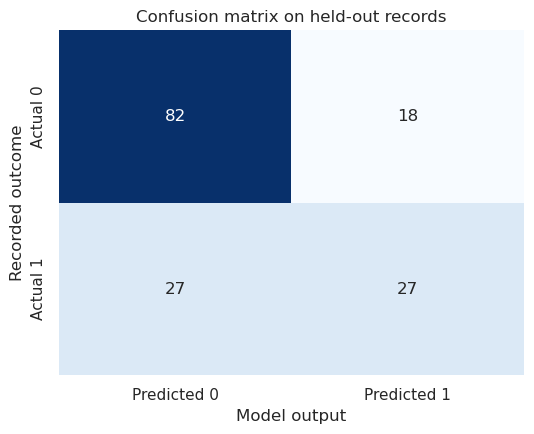

In [8]:
labels = [0, 1]
cm = confusion_matrix(df["actual"], df["predicted"], labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"], ax=ax)
ax.set(title="Confusion matrix on held-out records", xlabel="Model output", ylabel="Recorded outcome")
plt.tight_layout()
plt.show()



## 2. Compare features across correct and incorrect predictions

Each point is a held-out record. Look for differences between false negatives and true positives (both have actual outcome 1), and between false positives and true negatives (both have actual outcome 0). These are patterns in this dataset, not medical explanations.


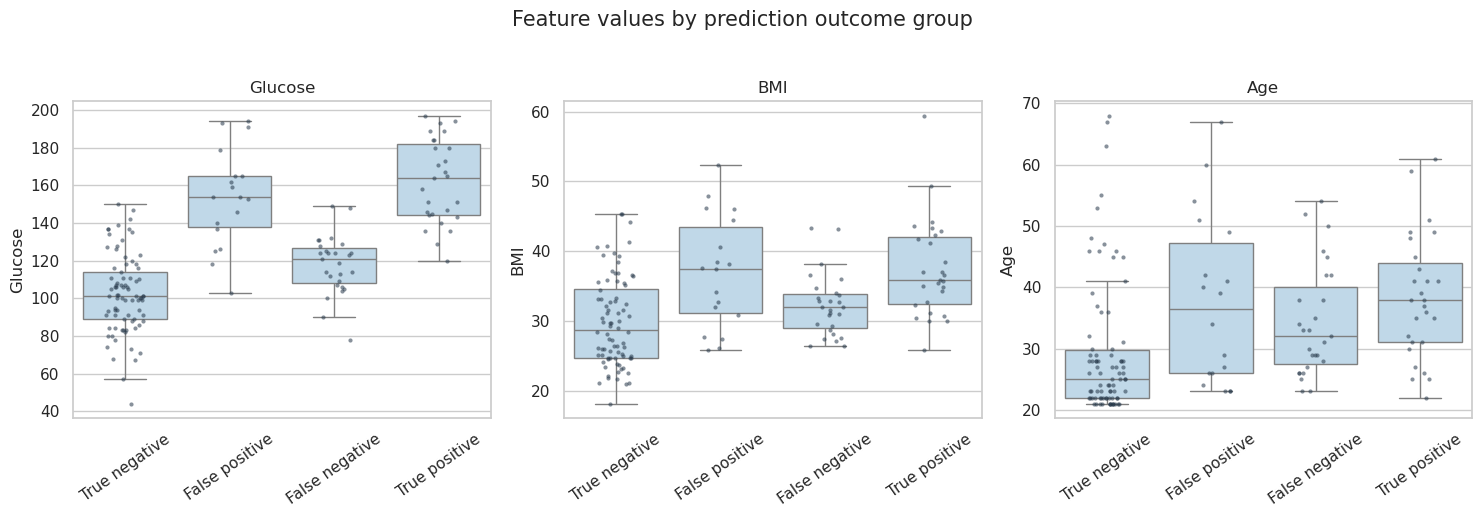

In [9]:
group_order = ["True negative", "False positive", "False negative", "True positive"]
feature_names = ["Glucose", "BMI", "Age"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, feature in zip(axes, feature_names):
    sns.boxplot(data=df_visual.dropna(subset=[feature]), x="error_group", y=feature, order=group_order, showfliers=False, color="#b9d9ef", ax=ax)
    sns.stripplot(data=df_visual.dropna(subset=[feature]), x="error_group", y=feature, order=group_order, color="#26384a", alpha=.55, size=3, jitter=.18, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("Feature values by prediction outcome group", y=1.03, fontsize=15)
plt.tight_layout()
plt.show()



## 3. Error rates across feature ranges

This chart checks whether the proportion of missed positive records (false-negative rate) or incorrectly flagged negative records (false-positive rate) changes across feature ranges. It displays the number of records in each bin so small groups are visible.



Glucose: counts and error rates by range


,bin,records,actual_1_n,false_negatives_n,false_negative_rate,actual_0_n,false_positives_n,false_positive_rate
0,"(43.999, 100.0]",42,3,3,1.000,39,0,0.000
1,"(100.0, 118.0]",37,9,9,1.000,28,2,0.071
2,"(118.0, 142.0]",36,18,13,0.722,18,4,0.222
3,"(142.0, 197.0]",38,24,2,0.083,14,12,0.857



BMI: counts and error rates by range


,bin,records,actual_1_n,false_negatives_n,false_negative_rate,actual_0_n,false_positives_n,false_positive_rate
0,"(18.198999999999998, 26.5]",39,3,2,0.667,36,2,0.056
1,"(26.5, 31.8]",37,16,11,0.688,21,3,0.143
2,"(31.8, 36.675]",38,20,11,0.550,18,3,0.167
3,"(36.675, 59.4]",38,15,3,0.200,23,10,0.435



Age: counts and error rates by range


,bin,records,actual_1_n,false_negatives_n,false_negative_rate,actual_0_n,false_positives_n,false_positive_rate
0,"(20.999, 23.0]",40,3,2,0.667,37,3,0.081
1,"(23.0, 28.0]",38,10,6,0.600,28,4,0.143
2,"(28.0, 39.75]",37,23,12,0.522,14,3,0.214
3,"(39.75, 68.0]",39,18,7,0.389,21,8,0.381


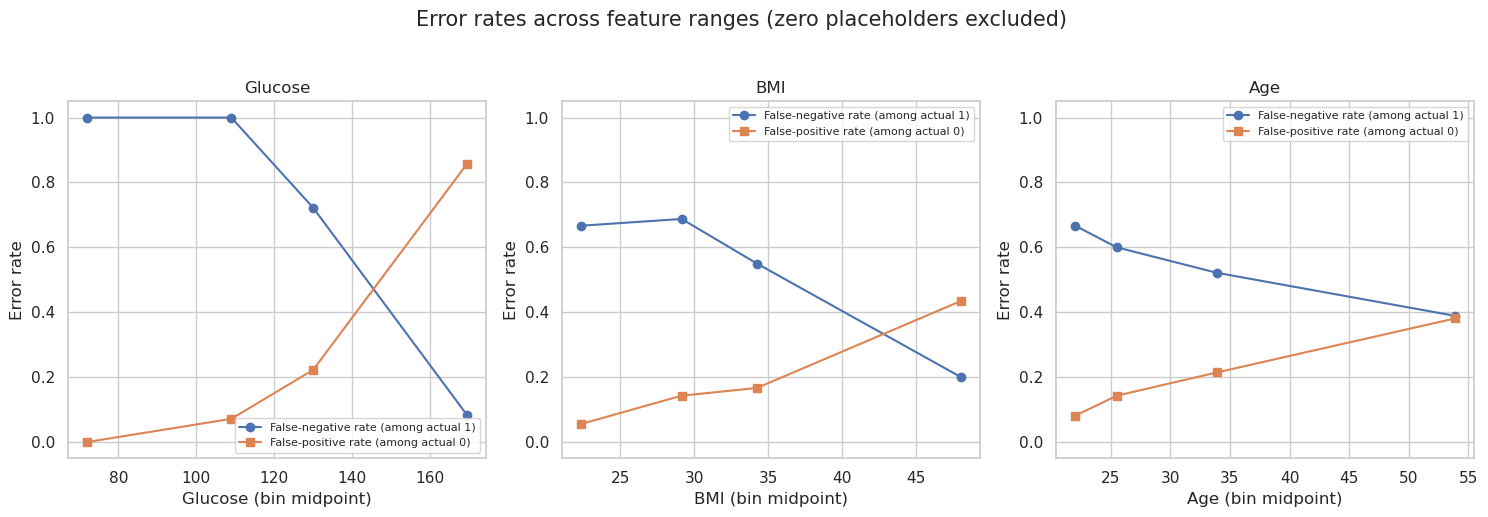

In [10]:
def make_bins(series, q=4):
    # Quantile bins keep groups reasonably populated; duplicates can reduce bin count.
    return pd.qcut(series, q=q, duplicates="drop")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, feature in zip(axes, feature_names):
    # Exclude medically implausible zero placeholders from these feature comparisons.
    temp = df_visual[[feature, "actual", "predicted"]].dropna(subset=[feature]).copy()
    temp["bin"] = make_bins(temp[feature])
    rows = []
    for interval, part in temp.groupby("bin", observed=True):
        positives = part[part.actual == 1]
        negatives = part[part.actual == 0]
        rows.append({
            "bin": str(interval),
            "midpoint": float((interval.left + interval.right) / 2),
            "records": len(part),
            "actual_1_n": len(positives),
            "false_negatives_n": int((positives.predicted == 0).sum()),
            "false_negative_rate": ((positives.predicted == 0).mean() if len(positives) else np.nan),
            "actual_0_n": len(negatives),
            "false_positives_n": int((negatives.predicted == 1).sum()),
            "false_positive_rate": ((negatives.predicted == 1).mean() if len(negatives) else np.nan),
        })
    summary = pd.DataFrame(rows).sort_values("midpoint")
    print(f"\n{feature}: counts and error rates by range")
    display(summary[["bin", "records", "actual_1_n", "false_negatives_n", "false_negative_rate",
                     "actual_0_n", "false_positives_n", "false_positive_rate"]].round(3))
    ax.plot(summary.midpoint, summary.false_negative_rate, marker="o", label="False-negative rate (among actual 1)")
    ax.plot(summary.midpoint, summary.false_positive_rate, marker="s", label="False-positive rate (among actual 0)")
    ax.set_ylim(-.05, 1.05)
    ax.set_title(feature)
    ax.set_xlabel(f"{feature} (bin midpoint)")
    ax.set_ylabel("Error rate")
    ax.legend(fontsize=8)
fig.suptitle("Error rates across feature ranges (zero placeholders excluded)", y=1.03, fontsize=15)
plt.tight_layout()
plt.show()



## 4. Explore decision-threshold changes

The saved `probability` is the model’s probability estimate for class 1. The plot below recalculates labels from that probability for several thresholds. Lower thresholds usually flag more records as positive, which can reduce false negatives but increase false positives. Verify what happens in these data.


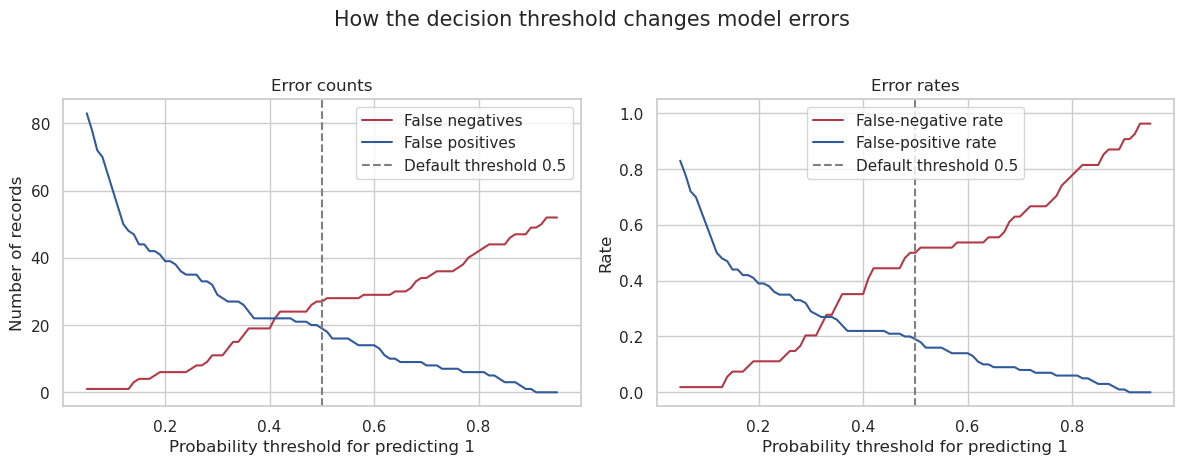

In [11]:
thresholds = np.linspace(0.05, 0.95, 91)
actual = df["actual"].to_numpy().astype(int)
probability = df["probability"].to_numpy()
rows = []
for threshold in thresholds:
    predicted_at_threshold = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predicted_at_threshold, labels=[0, 1]).ravel()
    rows.append({
        "threshold": threshold,
        "false_negatives": fn,
        "false_positives": fp,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else np.nan,
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else np.nan,
    })
threshold_summary = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(threshold_summary.threshold, threshold_summary.false_negatives, label="False negatives", color="#b23a48")
axes[0].plot(threshold_summary.threshold, threshold_summary.false_positives, label="False positives", color="#315a9b")
axes[0].axvline(0.5, color="gray", linestyle="--", label="Default threshold 0.5")
axes[0].set(xlabel="Probability threshold for predicting 1", ylabel="Number of records", title="Error counts")
axes[0].legend()
axes[1].plot(threshold_summary.threshold, threshold_summary.false_negative_rate, label="False-negative rate", color="#b23a48")
axes[1].plot(threshold_summary.threshold, threshold_summary.false_positive_rate, label="False-positive rate", color="#315a9b")
axes[1].axvline(0.5, color="gray", linestyle="--", label="Default threshold 0.5")
axes[1].set(xlabel="Probability threshold for predicting 1", ylabel="Rate", title="Error rates", ylim=(-.05, 1.05))
axes[1].legend()
fig.suptitle("How the decision threshold changes model errors", y=1.03, fontsize=15)
plt.tight_layout()
plt.show()

